In [1]:
from utils import add_project_root_to_sys_path
add_project_root_to_sys_path()
import polars as pl
from pathlib import Path
from functools import partial
import json
from neuralnet.datasets.ringer import RingerParquetDataset
from neuralnet.workflows.ringer.training import RingerKerasTrainingJob
from neuralnet import get_logger
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import mplhep as hep
from itertools import product, combinations
import numpy as np

logger = get_logger()

2026-08-17 14:03:37.417434: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-08-17 14:03:37.437106: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-17 14:03:38.085149: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-08-17 14:03:40.307634: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off,

In [2]:
models = {
    'fp': {
        'directory': Path('/home/lucasbanunes/data/neuralnet_jobs/sbrt/mlp_v0_sbrt_threshold_fit'),
        'training_job_dir': Path('/home/lucasbanunes/data/neuralnet_jobs/sbrt/mlp_v0'),
        'label': 'FP',
        'color': 'blue'
    },
    'ptq': {
        'directory': Path('/home/lucasbanunes/data/neuralnet_jobs/sbrt/ptq_mlp_v0_sbrt_threshold_fit'),
        'training_job_dir': Path('/home/lucasbanunes/data/neuralnet_jobs/sbrt/mlp_v0'),
        'label': 'PTQ',
        'color': 'green'
    },
    'qat': {
        'directory': Path('/home/lucasbanunes/data/neuralnet_jobs/sbrt/qat_mlp_v1_sbrt_threshold_fit'),
        'training_job_dir': Path('/home/lucasbanunes/data/neuralnet_jobs/sbrt/qat_mlp_v1'),
        'label': 'QAT',
        'color': 'red'
    }
}

In [3]:
def rename_function(col_name, prefix: str):
    if 'et_bin' in col_name:
        return col_name
        
    if 'eta_bin' in col_name:
        return col_name
    
    return f'{prefix}.{col_name}'

join_cols = [
    'et_bin.low',
    'et_bin.high',
    'et_bin.closed',
    'eta_bin.low',
    'eta_bin.high',
    'eta_bin.closed'
]
results_df = None
for i, (model, model_info) in enumerate(models.items()):
    models[model]['results'] = (
        pl.scan_parquet(model_info['directory'] / 'results.parquet')
        .rename(partial(rename_function, prefix=model))
    )
    committee_results_path = model_info['directory'] / 'committee_results.json'
    with committee_results_path.open('r') as f:
        models[model]['committee_results']= json.load(f)
    if i:
        results_df = results_df.join(models[model]['results'], on=join_cols)
    else:
        results_df = models[model]['results']
results_df = results_df.collect()
results_df

fp.fold,fp.init,et_bin.low,et_bin.high,et_bin.closed,eta_bin.low,eta_bin.high,eta_bin.closed,fp.history.start,fp.history.end,fp.history.train.accuracy,fp.history.train.loss,fp.history.val.accuracy,fp.history.val.loss,fp.history.val.max_sp,fp.history.val.max_sp_fa,fp.history.val.max_sp_pd,fp.history.val.max_sp_threshold,fp.history.val.max_sp_best_epoch,fp.fit.train.accuracy,fp.fit.train.loss,fp.fit.val.accuracy,fp.fit.val.loss,fp.fit.val.max_sp,fp.fit.val.max_sp_fa,fp.fit.val.max_sp_pd,fp.fit.val.max_sp_threshold,fp.fit.val.max_sp_best_epoch,fp.id,fp.train.tight.tp,fp.train.tight.fp,fp.train.tight.positives,fp.train.tight.negatives,fp.train.tight.fn,fp.train.tight.tn,fp.train.tight.total,fp.train.tight.correct,…,qat.test.medium.ref.tpr,qat.test.medium.ref.color,qat.test.medium.ref.label,qat.test.loose.tp,qat.test.loose.fp,qat.test.loose.positives,qat.test.loose.negatives,qat.test.loose.fn,qat.test.loose.tn,qat.test.loose.total,qat.test.loose.correct,qat.test.loose.incorrect,qat.test.loose.tpr,qat.test.loose.fpr,qat.test.loose.accuracy,qat.test.loose.sp,qat.test.loose.relative_tpr_err,qat.test.loose.ref.tpr,qat.test.loose.ref.color,qat.test.loose.ref.label,qat.test.very_loose.tp,qat.test.very_loose.fp,qat.test.very_loose.positives,qat.test.very_loose.negatives,qat.test.very_loose.fn,qat.test.very_loose.tn,qat.test.very_loose.total,qat.test.very_loose.correct,qat.test.very_loose.incorrect,qat.test.very_loose.tpr,qat.test.very_loose.fpr,qat.test.very_loose.accuracy,qat.test.very_loose.sp,qat.test.very_loose.relative_tpr_err,qat.test.very_loose.ref.tpr,qat.test.very_loose.ref.color,qat.test.very_loose.ref.label
i64,i64,f64,str,str,f64,f64,str,str,str,list[f64],list[f64],list[f64],list[f64],list[f64],list[f64],list[f64],list[f64],list[i64],f64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,…,f64,str,str,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,str,str,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,str,str
3,3,20000.0,"""30000.0""","""left""",2.37,2.5,"""left""","""2026-08-05T22:33:27.921104""","""2026-08-05T22:34:22.684578""","[0.37442, 0.500956, … 0.956638]","[0.684724, 0.680673, … 0.111119]","[0.423045, 0.614819, … 0.955326]","[0.6919, 0.684184, … 0.118385]","[0.939858, 0.899868, … 0.969757]","[0.080888, 0.11142, … 0.051546]","[0.960836, 0.911227, … 0.991297]","[0.515551, 0.513216, … 0.59777]","[0, 0, … 232]",0.955955,0.113001,0.954236,0.119889,0.969928,0.050357,0.990426,0.618525,232,243,4723,738,4747,9897,24,9159,14644,13882,…,0.996,"""orange""","""Medium""",5878,993,5896,12419,18,11426,18315,17304,1011,0.996947,0.079958,0.944799,0.958109,0.005308,0.997,"""green""","""Loose""",5884,1149,5896,12419,12,11270,18315,17154,1161,0.997965,0.09252,0.936609,0.952185,0.003535,0.998,"""blue""","""Loose"""
4,4,50000.0,"""Infinity""","""left""",1.52,2.37,"""left""","""2026-08-05T23:18:47.430763""","""2026-08-05T23:19:41.699967""","[0.847756, 0.931623, … 0.993171]","[0.681182, 0.656713, … 0.039059]","[0.902258, 0.937744, … 0.994509]","[0.652053, 0.617001, … 0.03018]","[0.974515, 0.973659, … 0.991292]","[0.031028, 0.03215, … 0.014206]","[0.980074, 0.979485, … 0.996805]","[0.518096, 0.528537, … 0.469838]","[0, 0, … 153]",0.993085,0.039704,0.994646,0.030278,0.991521,0.013832,0.996889,0.5033,153,599,47554,193,47793,10633,239,10440,58426,57994,…,0.996,"""orange""","""Medium""",59508,257,59687,13308,179,13051,72995,72559,436,0.997001,0.019312,0.994027,0.988828,0.000103,0.997,"""green""","""Loose""",59568,302,59687,13308,119,13006,72995,72574,421,0.998006,0.022693,0.994232,0.987629,0.000628,0.998,"""blue""","""Loose"""
4,1,40000.0,"""50000.0""","""left""",0.0,0.8,"""left""","""2026-08-05T22:52:44.854767""","""2026-08-05T22:54:12.016679""","[0.973459, 0.996234, … 0.995727]","[0.618495, 0.406622, … 0.02481]","[0.995584, 0.996312, … 0.995831]","[0.53637, 0.312833, … 0.017952]","[0.982402, 0.986816, … 0.994205]","[0.021107, 0.017647, … 0.008651]","[0.985918, 0.991288, … 0.997064]","[0.5348, 0.601898, …

In [4]:
results_df.schema

Schema([('fp.fold', Int64),
        ('fp.init', Int64),
        ('et_bin.low', Float64),
        ('et_bin.high', String),
        ('et_bin.closed', String),
        ('eta_bin.low', Float64),
        ('eta_bin.high', Float64),
        ('eta_bin.closed', String),
        ('fp.history.start', String),
        ('fp.history.end', String),
        ('fp.history.train.accuracy', List(Float64)),
        ('fp.history.train.loss', List(Float64)),
        ('fp.history.val.accuracy', List(Float64)),
        ('fp.history.val.loss', List(Float64)),
        ('fp.history.val.max_sp', List(Float64)),
        ('fp.history.val.max_sp_fa', List(Float64)),
        ('fp.history.val.max_sp_pd', List(Float64)),
        ('fp.history.val.max_sp_threshold', List(Float64)),
        ('fp.history.val.max_sp_best_epoch', List(Int64)),
        ('fp.fit.train.accuracy', Float64),
        ('fp.fit.train.loss', Float64),
        ('fp.fit.val.accuracy', Float64),
        ('fp.fit.val.loss', Float64),
        ('fp.fit.val.

In [5]:
def format_et_bin_high(value) -> str:

    if value == 'Infinity':
        return '\\infty'
    
    return str(round(float(value)*1e-3))    

def format_float(x, scientific_notation: bool, label: str, decimals: int = 2) -> str:
    if scientific_notation:
        return f'{label}: {x:.{decimals}e}'
    
    return f'{label}: {x:.{decimals}f}'

def get_metrics(
    results_df: pl.LazyFrame | pl.DataFrame,
    metrics: list[dict]
) -> pl.LazyFrame | pl.DataFrame:

    metric_names = []

    for i, metric in enumerate(metrics):
        scientific_notation = metric.get('scientific_notation', False)
        mapper = partial(format_float, scientific_notation=scientific_notation, label=metric['label'], decimals=metric.get('decimals', 2))
        expr = pl.col(metric['name'])
        if metric.get('percentage', False):
            expr *= 100
        expr = expr.map_elements(mapper, return_dtype=pl.String)
        results_df = results_df.with_columns(expr)
        metric_names.append(metric['name'])

    return (
        results_df
        .sort([pl.col('et_bin.low'), pl.col('eta_bin.low')])
        .with_columns(
            pl.col('et_bin.low').map_elements(format_et_bin_high, return_dtype=pl.String),
            pl.col('et_bin.high').map_elements(format_et_bin_high, return_dtype=pl.String),
            pl.concat_str([pl.col(metric_name) for metric_name in metric_names], separator=r' \\ ').alias('metrics')
        )
        .select(
            pl.format('\\makecell[r]{{{}}}', pl.col('metrics')).alias('metrics'),
            pl.format('$[{}, {})$', pl.col('et_bin.low'), pl.col('et_bin.high')).alias('et'),
            pl.format('$[{}, {})$', pl.col('eta_bin.low'), pl.col('eta_bin.high')).alias('eta'),
        )
        .pivot(values=pl.col('metrics'), index=pl.col('et'), columns=pl.col('eta'))
    )

def get_diff(
    results_df: pl.LazyFrame | pl.DataFrame,
    metrics: list[dict],
    scientific_notation: bool = False,
    relative: bool = False
):
    diff_df = results_df
    metric_names = []

    for i, metric in enumerate(metrics):

        mapper = partial(format_float, scientific_notation=scientific_notation, label=metric['label'])
        diff = pl.col(metric['candidate_col']) - pl.col(metric['ref_col'])
        if relative:
            diff = diff.truediv(pl.col(metric['ref_col']))

        metric_col_name = f'diff_{i}'
        diff_df = (
            diff_df
            .with_columns(
                diff
                .mul(100)
                .map_elements(mapper, return_dtype=pl.String)
                .alias(metric_col_name))
        )
        metric_names.append(metric_col_name)

    diff_df = (
        diff_df
        .sort([pl.col('et_bin.low'), pl.col('eta_bin.low')])
        .with_columns(
            pl.col('et_bin.low').map_elements(format_et_bin_high, return_dtype=pl.String),
            pl.col('et_bin.high').map_elements(format_et_bin_high, return_dtype=pl.String),
        )
        .with_columns(pl.concat_str([pl.col(metric_name) for metric_name in metric_names], separator=r' \\ ').alias('diff'))
        .select(
            pl.format('\\makecell[r]{{{}}}', pl.col('diff')).alias('diff'),
            pl.format('$[{}, {})$', pl.col('et_bin.low'), pl.col('et_bin.high')).alias('et'),
            pl.format('$[{}, {})$', pl.col('eta_bin.low'), pl.col('eta_bin.high')).alias('eta'),
        )
        
    )

    return diff_df


In [27]:
metrics_table_filepath = Path('tables.tex')
table_strings = []
data_types = [
    'train', 'val', 'test'
]
criteria = ['tight', 'medium', 'loose', 'very_loose']
for model, model_info in models.items():
    table_strings.append(f'\\section{{{model_info["label"]}}}\n\n')
    for data_type, criterion in product(data_types, criteria):
        print(f'Running {model} {data_type} {criterion}')
        frame_name = f'{model_info["label"]} {data_type} {criterion} Results'
        table_strings.append(
            f'\\begin{{frame}}{{{frame_name}}}\n'
        )
        metrics_df = get_metrics(
            results_df,
            metrics=[
                {
                    'name': f'{model}.{data_type}.{criterion}.sp',
                    'scientific_notation': False,
                    'label': 'SP',
                    'percentage': True,
                    'decimals': 3
                },
                {
                    'name': f'{model}.{data_type}.{criterion}.tpr',
                    'scientific_notation': False,
                    'label': 'PD',
                    'percentage': True,
                    'decimals': 3
                },
                {
                    'name': f'{model}.{data_type}.{criterion}.fpr',
                    'scientific_notation': False,
                    'label': 'FA',
                    'percentage': True,
                    'decimals': 3
                },
            ]
        )
        latex_string = metrics_df.to_pandas().to_latex(index=False)
        table_strings.append('\\begin{adjustbox}{height=0.5\\textheight, center}\n')
        table_strings.append(latex_string)
        table_strings.append('\\end{adjustbox}\n')
        table_strings.append(
            '\\end{frame}\n\n'
        )
metrics_table_filepath.write_text(''.join(table_strings))

Running fp train tight
Running fp train medium
Running fp train loose
Running fp train very_loose
Running fp val tight
Running fp val medium
Running fp val loose


/tmp/ipykernel_9434/2660348581.py:44: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(values=pl.col('metrics'), index=pl.col('et'), columns=pl.col('eta'))
/tmp/ipykernel_9434/2660348581.py:44: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(values=pl.col('metrics'), index=pl.col('et'), columns=pl.col('eta'))
/tmp/ipykernel_9434/2660348581.py:44: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(values=pl.col('metrics'), index=pl.col('et'), columns=pl.col('eta'))
/tmp/ipykernel_9434/2660348581.py:44: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(values=pl.col('metrics'), index=pl.col('et'), columns=pl.col('eta'))
/tmp/ipykernel_9434/2660348581.py:44: DeprecationWar

Running fp val very_loose
Running fp test tight
Running fp test medium
Running fp test loose
Running fp test very_loose
Running ptq train tight
Running ptq train medium
Running ptq train loose
Running ptq train very_loose
Running ptq val tight
Running ptq val medium
Running ptq val loose
Running ptq val very_loose


/tmp/ipykernel_9434/2660348581.py:44: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(values=pl.col('metrics'), index=pl.col('et'), columns=pl.col('eta'))
/tmp/ipykernel_9434/2660348581.py:44: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(values=pl.col('metrics'), index=pl.col('et'), columns=pl.col('eta'))
/tmp/ipykernel_9434/2660348581.py:44: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(values=pl.col('metrics'), index=pl.col('et'), columns=pl.col('eta'))
/tmp/ipykernel_9434/2660348581.py:44: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(values=pl.col('metrics'), index=pl.col('et'), columns=pl.col('eta'))
/tmp/ipykernel_9434/2660348581.py:44: DeprecationWar

Running ptq test tight
Running ptq test medium
Running ptq test loose
Running ptq test very_loose
Running qat train tight
Running qat train medium
Running qat train loose
Running qat train very_loose
Running qat val tight
Running qat val medium
Running qat val loose


/tmp/ipykernel_9434/2660348581.py:44: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(values=pl.col('metrics'), index=pl.col('et'), columns=pl.col('eta'))
/tmp/ipykernel_9434/2660348581.py:44: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(values=pl.col('metrics'), index=pl.col('et'), columns=pl.col('eta'))
/tmp/ipykernel_9434/2660348581.py:44: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(values=pl.col('metrics'), index=pl.col('et'), columns=pl.col('eta'))
/tmp/ipykernel_9434/2660348581.py:44: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(values=pl.col('metrics'), index=pl.col('et'), columns=pl.col('eta'))
/tmp/ipykernel_9434/2660348581.py:44: DeprecationWar

Running qat val very_loose
Running qat test tight
Running qat test medium
Running qat test loose
Running qat test very_loose


/tmp/ipykernel_9434/2660348581.py:44: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(values=pl.col('metrics'), index=pl.col('et'), columns=pl.col('eta'))
/tmp/ipykernel_9434/2660348581.py:44: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(values=pl.col('metrics'), index=pl.col('et'), columns=pl.col('eta'))
/tmp/ipykernel_9434/2660348581.py:44: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(values=pl.col('metrics'), index=pl.col('et'), columns=pl.col('eta'))
/tmp/ipykernel_9434/2660348581.py:44: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(values=pl.col('metrics'), index=pl.col('et'), columns=pl.col('eta'))


61278

In [6]:
diff = get_diff(
    results_df,
    scientific_notation=False,
    metrics=[
        {
            'ref_col': 'fp.val.medium.sp',
            'candidate_col': 'qat.val.medium.sp',
            'label': 'SP'
        },
        {
            'ref_col': 'fp.val.medium.tpr',
            'candidate_col': 'qat.val.medium.tpr',
            'label': 'PD'
        },
        {
            'ref_col': 'fp.val.medium.fpr',
            'candidate_col': 'qat.val.medium.fpr',
            'label': 'FA'
        }
    ],
    relative=True
)
latex_string = diff.to_pandas().to_latex(index=False)
print(latex_string)

\begin{tabular}{lll}
\toprule
diff & et & eta \\
\midrule
\makecell[r]{SP: 0.12 \\ PD: 0.00 \\ FA: -3.73} & $[15, 20)$ & $[0.0, 0.8)$ \\
\makecell[r]{SP: 0.25 \\ PD: 0.00 \\ FA: -4.50} & $[15, 20)$ & $[0.8, 1.37)$ \\
\makecell[r]{SP: -0.28 \\ PD: 0.00 \\ FA: 3.41} & $[15, 20)$ & $[1.37, 1.52)$ \\
\makecell[r]{SP: 0.37 \\ PD: -0.00 \\ FA: -8.74} & $[15, 20)$ & $[1.52, 2.37)$ \\
\makecell[r]{SP: 0.00 \\ PD: 0.00 \\ FA: 0.00} & $[15, 20)$ & $[2.37, 2.5)$ \\
\makecell[r]{SP: 0.00 \\ PD: 0.00 \\ FA: 0.00} & $[20, 30)$ & $[0.0, 0.8)$ \\
\makecell[r]{SP: 0.02 \\ PD: 0.00 \\ FA: -0.66} & $[20, 30)$ & $[0.8, 1.37)$ \\
\makecell[r]{SP: -0.87 \\ PD: 0.00 \\ FA: 12.17} & $[20, 30)$ & $[1.37, 1.52)$ \\
\makecell[r]{SP: 0.14 \\ PD: -0.00 \\ FA: -5.56} & $[20, 30)$ & $[1.52, 2.37)$ \\
\makecell[r]{SP: 0.04 \\ PD: 0.00 \\ FA: -1.03} & $[20, 30)$ & $[2.37, 2.5)$ \\
\makecell[r]{SP: 0.01 \\ PD: 0.00 \\ FA: -1.44} & $[30, 40)$ & $[0.0, 0.8)$ \\
\makecell[r]{SP: 0.02 \\ PD: 0.00 \\ FA: -1.40} & $[30, 40)$

In [7]:
rel_diff = get_diff(
    results_df,
    relative=True,
    scientific_notation=False,
    metrics=[
        {
            'ref_col': 'fp.val.medium.sp',
            'candidate_col': 'qat.val.medium.sp',
            'label': 'SP'
        },
        {
            'ref_col': 'fp.val.medium.tpr',
            'candidate_col': 'qat.val.medium.tpr',
            'label': 'PD'
        },
        {
            'ref_col': 'fp.val.medium.fpr',
            'candidate_col': 'qat.val.medium.fpr',
            'label': 'FA'
        }
    ]
)
latex_string = rel_diff.to_pandas().to_latex(index=False)
print(latex_string)

\begin{tabular}{llllll}
\toprule
et & $[0.0, 0.8)$ & $[0.8, 1.37)$ & $[1.37, 1.52)$ & $[1.52, 2.37)$ & $[2.37, 2.5)$ \\
\midrule
$[15, 20)$ & \makecell[r]{SP: -0.41 \\ PD: 0.10 \\ FA: 14.66} & \makecell[r]{SP: 0.12 \\ PD: 0.05 \\ FA: -1.64} & \makecell[r]{SP: -0.42 \\ PD: 0.20 \\ FA: 6.55} & \makecell[r]{SP: 0.24 \\ PD: 0.11 \\ FA: -4.26} & \makecell[r]{SP: 0.00 \\ PD: 0.00 \\ FA: 0.00} \\
$[20, 30)$ & \makecell[r]{SP: -0.10 \\ PD: 0.10 \\ FA: 8.46} & \makecell[r]{SP: -0.25 \\ PD: 0.10 \\ FA: 9.94} & \makecell[r]{SP: -1.59 \\ PD: 0.10 \\ FA: 22.96} & \makecell[r]{SP: -0.06 \\ PD: 0.10 \\ FA: 4.35} & \makecell[r]{SP: -0.10 \\ PD: 0.17 \\ FA: 4.64} \\
$[30, 40)$ & \makecell[r]{SP: -0.02 \\ PD: 0.10 \\ FA: 7.19} & \makecell[r]{SP: -0.12 \\ PD: 0.10 \\ FA: 13.99} & \makecell[r]{SP: -0.58 \\ PD: 0.11 \\ FA: 10.62} & \makecell[r]{SP: -0.14 \\ PD: 0.10 \\ FA: 13.86} & \makecell[r]{SP: -0.16 \\ PD: 0.12 \\ FA: 8.82} \\
$[40, 50)$ & \makecell[r]{SP: -0.00 \\ PD: 0.10 \\ FA: 12.50} & \makecell[r

/tmp/ipykernel_85224/3572304636.py:54: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(values=pl.col('diff'), index=pl.col('et'), columns=pl.col('eta'))


/tmp/ipykernel_85224/779785937.py:26: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots()


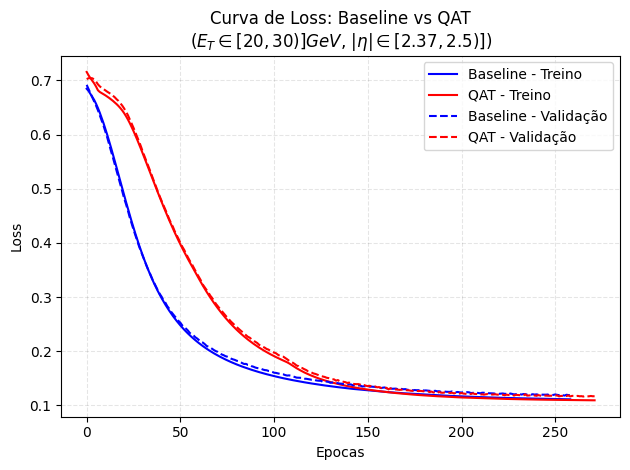

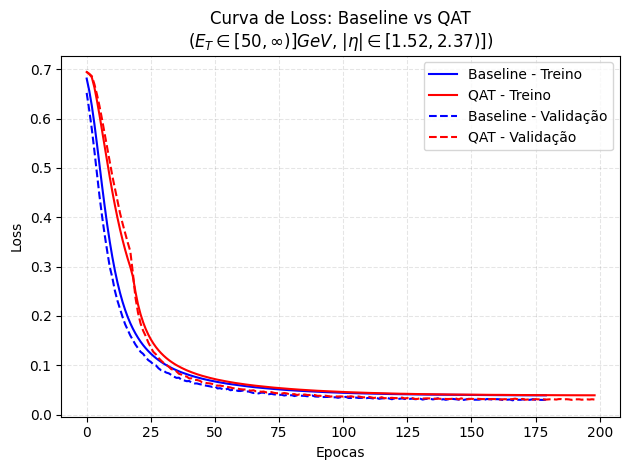

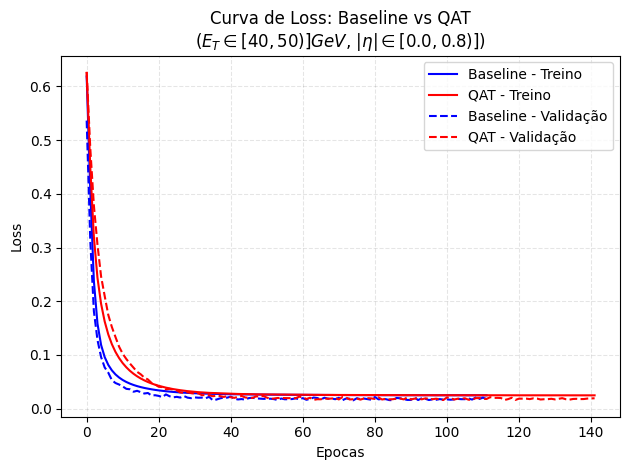

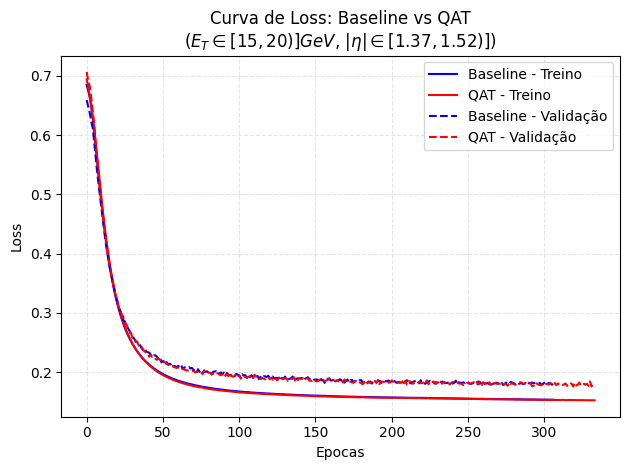

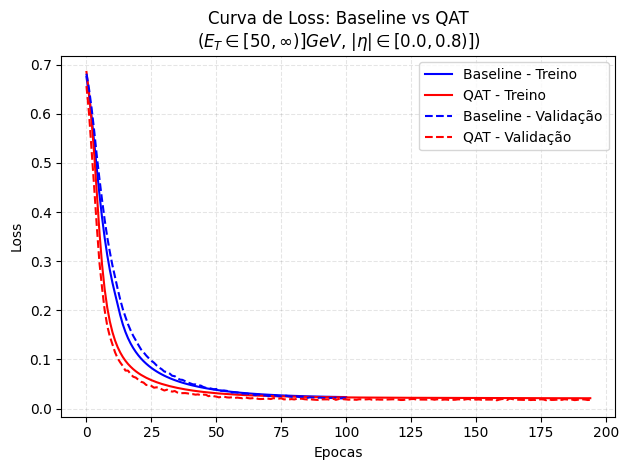

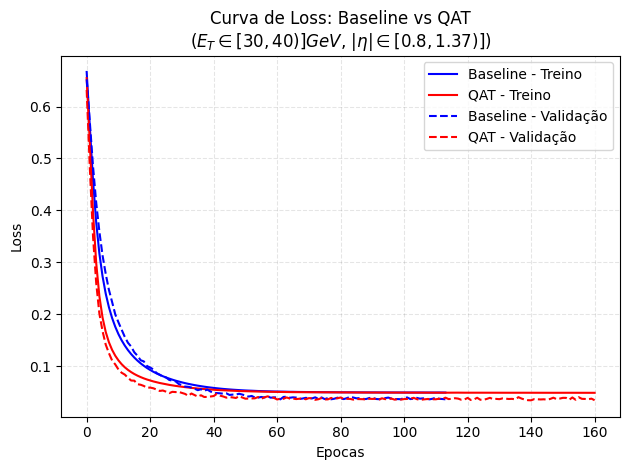

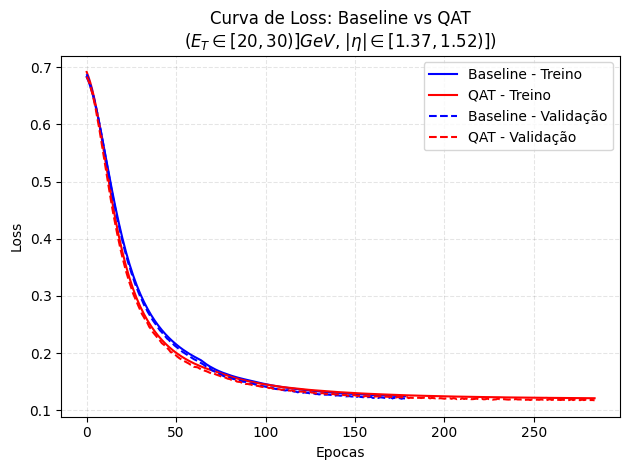

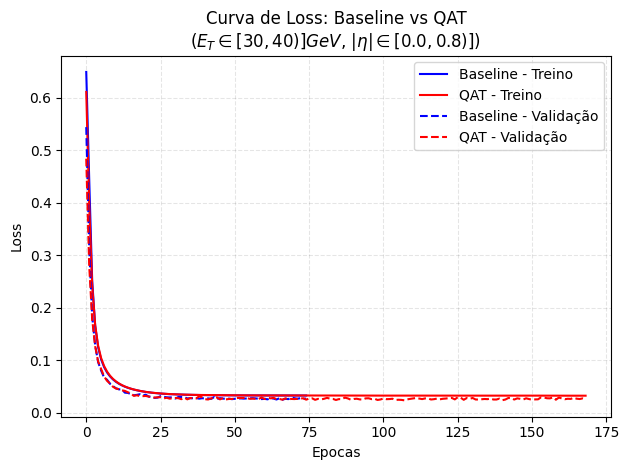

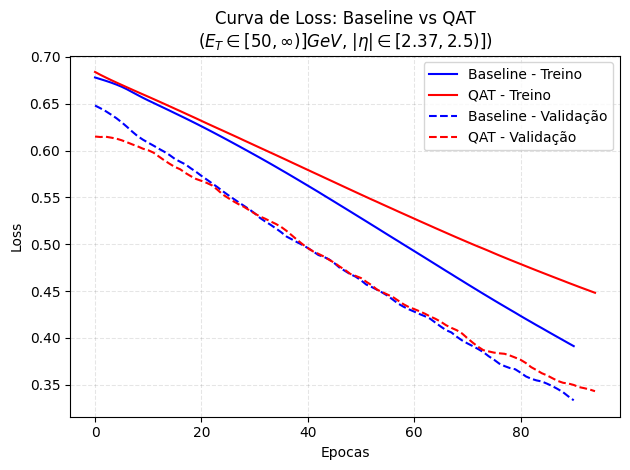

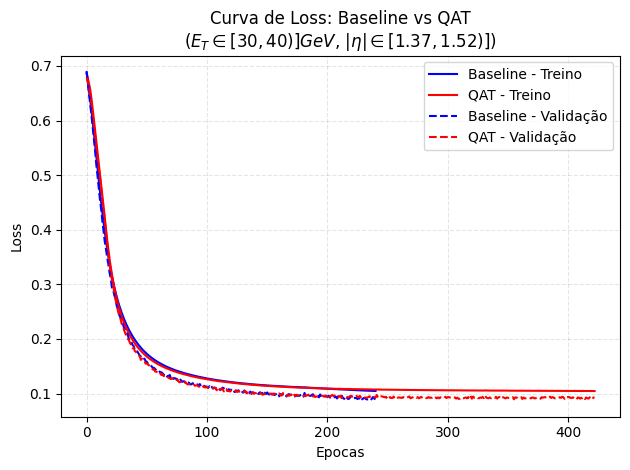

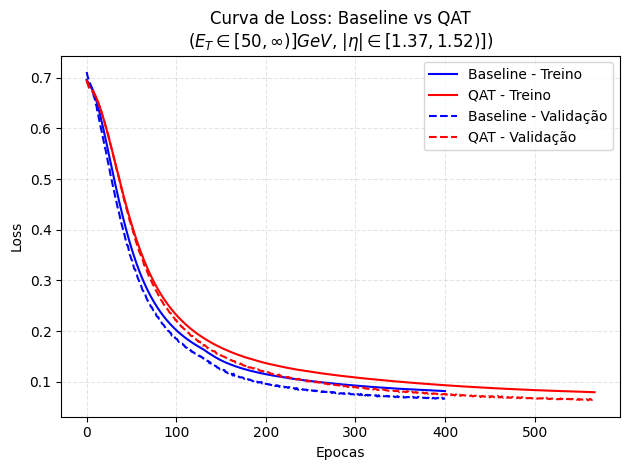

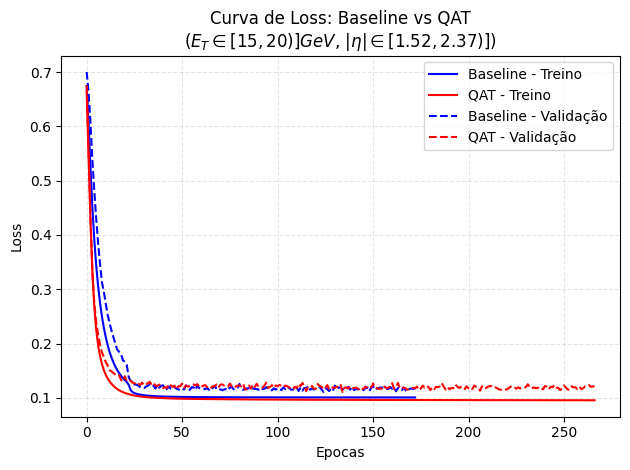

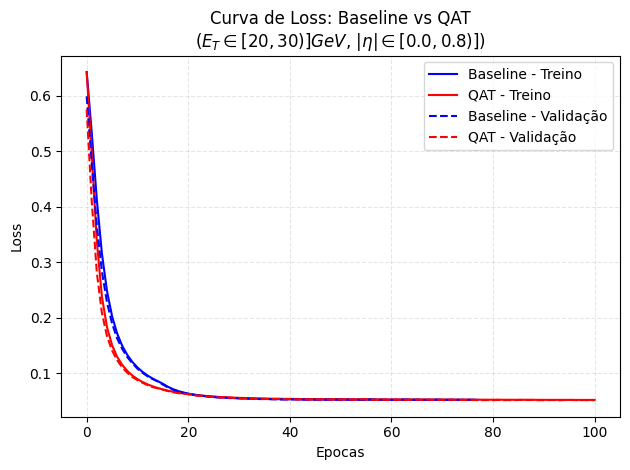

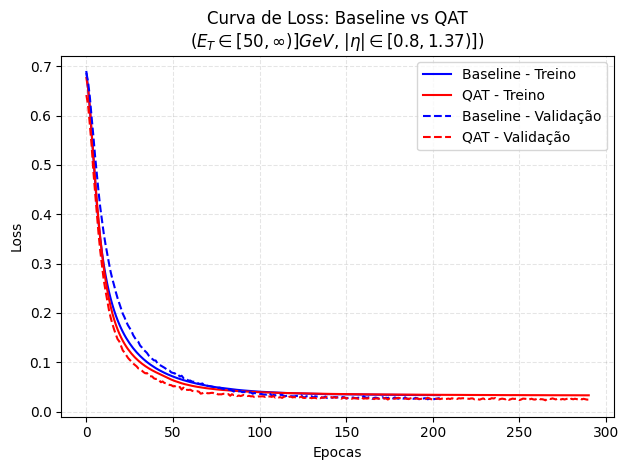

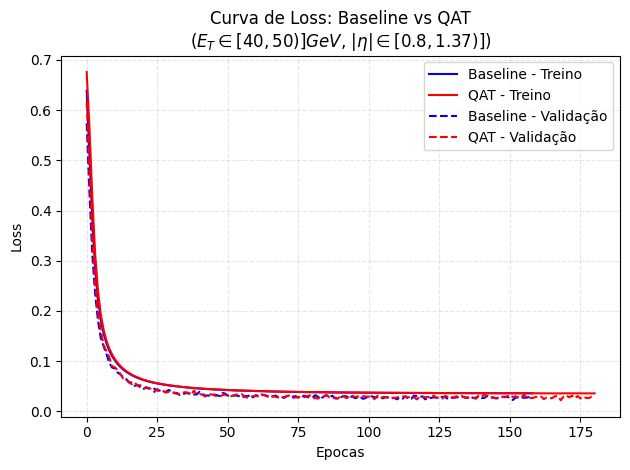

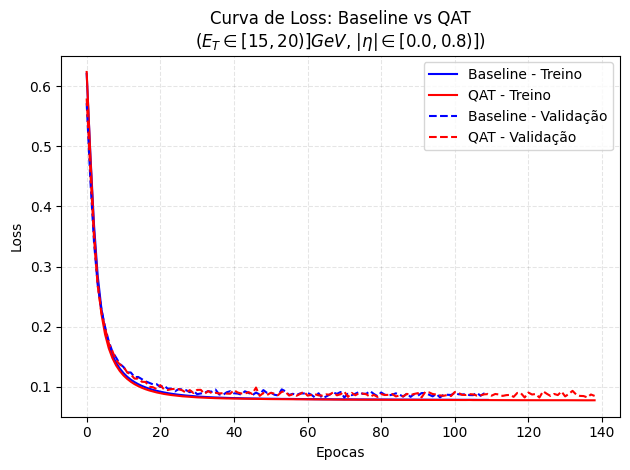

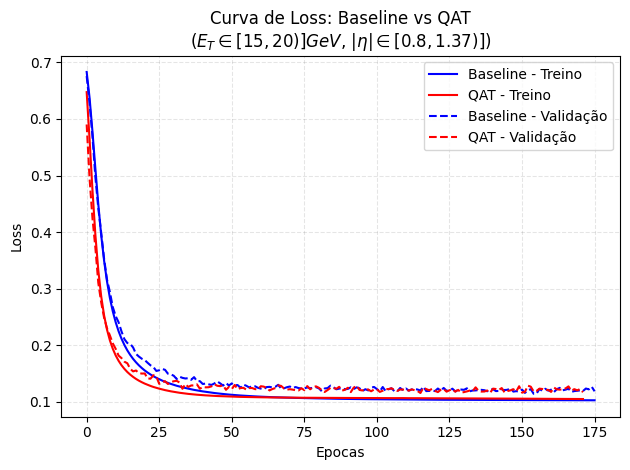

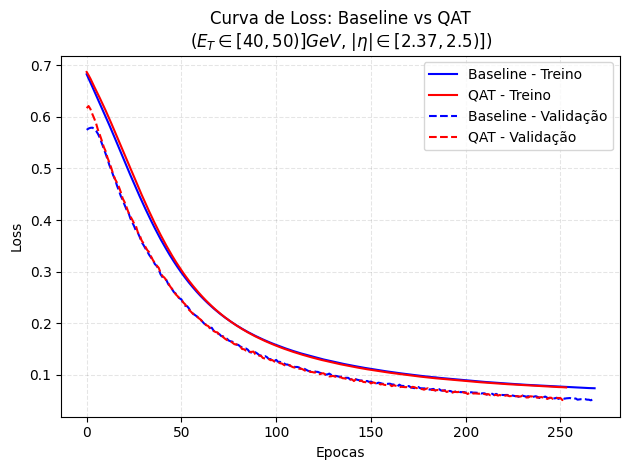

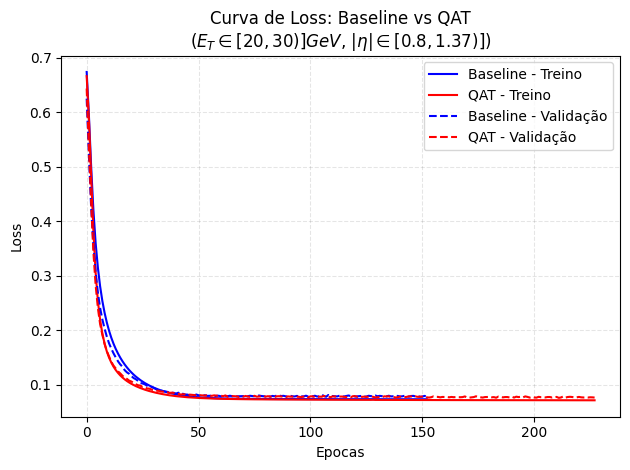

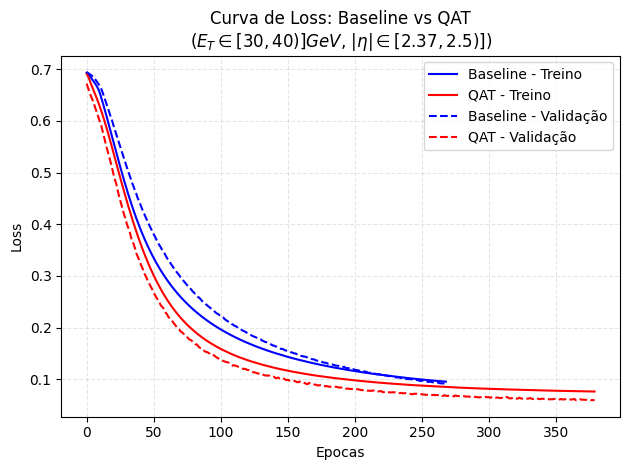

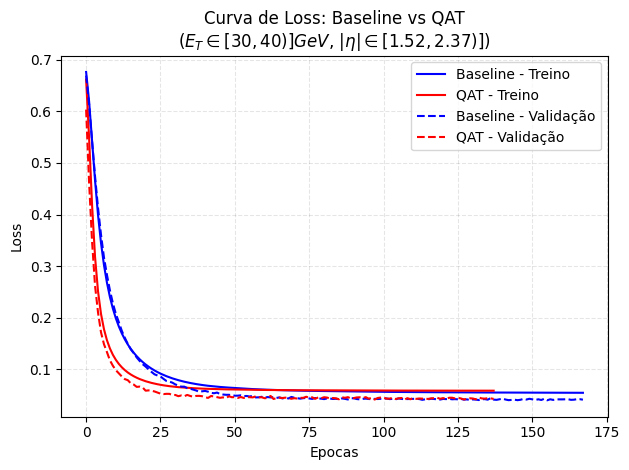

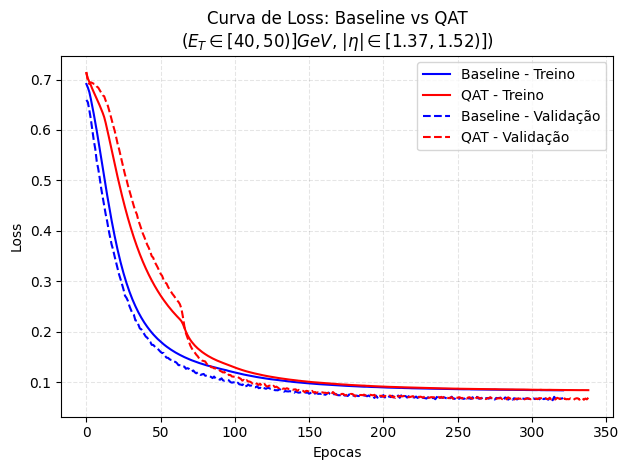

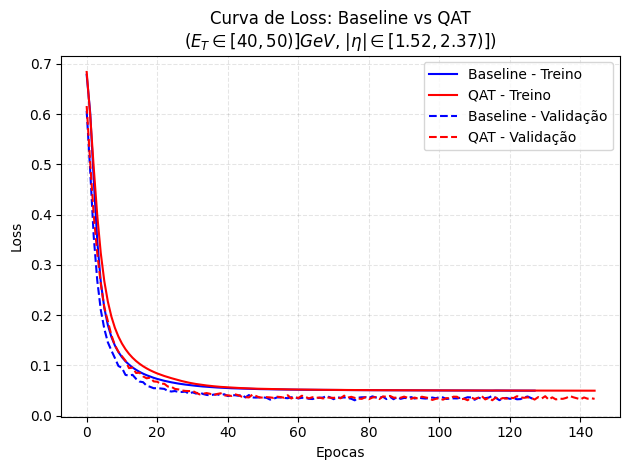

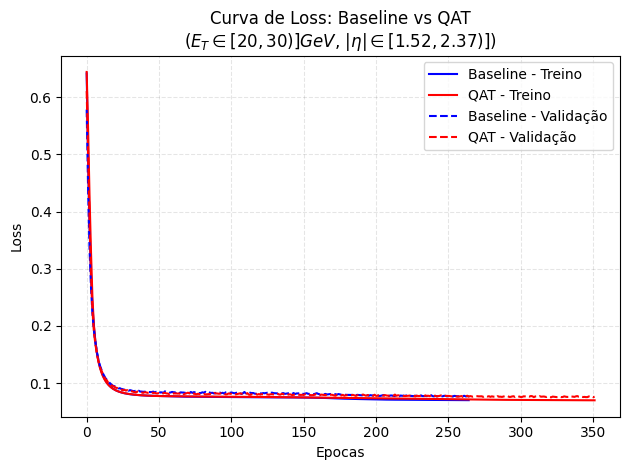

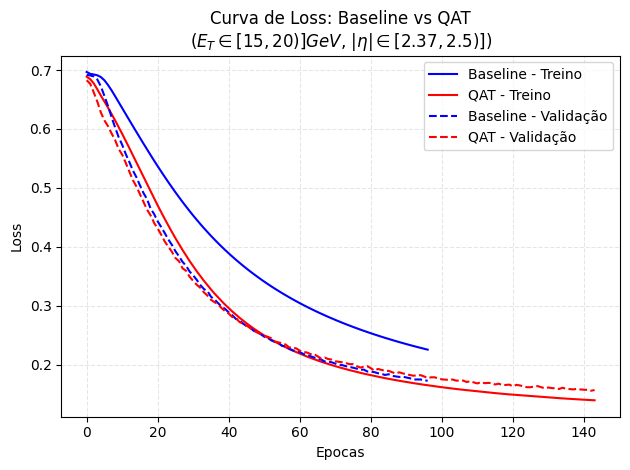

In [8]:
metrics_to_plot = {
    'fp.history.train.loss': {
        'linestyle': '-',
        'color': models['fp']['color'],
        'label': 'Baseline - Treino'
    },
    'qat.history.train.loss': {
        'linestyle': '-',
        'color': models['qat']['color'],
        'label': 'QAT - Treino'
    },
    'fp.history.val.loss': {
        'linestyle': '--',
        'color': models['fp']['color'],
        'label': 'Baseline - Validação'
    },
    'qat.history.val.loss': {
        'linestyle': '--',
        'color': models['qat']['color'],
        'label': 'QAT - Validação'
    },
}


for row in results_df.iter_rows(named=True):
    fig, ax = plt.subplots()
    ax.grid(linestyle="--", alpha=0.1, color="k")
    ax.set_xlabel('Epocas')
    ax.set_ylabel('Loss')
    et_bin_low = int(row['et_bin.low']*1e-3)
    et_bin_high = row['et_bin.high']
    if et_bin_high == 'Infinity':
        et_bin_high = '\\infty'
    else:
        et_bin_high = int(float(et_bin_high)*1e-3)
    eta_bin_low = row['eta_bin.low']
    eta_bin_high = row['eta_bin.high']
    ax.set_title(f'Curva de Loss: Baseline vs QAT\n$(E_T \\in [{et_bin_low}, {et_bin_high})] GeV$, $|\\eta| \\in [{eta_bin_low}, {eta_bin_high})])$')
    for metric_key, metric_info in metrics_to_plot.items():
        ax.plot(
            np.arange(len(row[metric_key])),
            row[metric_key],
            **metric_info
        )
    ax.legend()
    fig.tight_layout()


In [9]:
dataset_dir = Path('/home/lucasbanunes/data/ringer-datasets/datasets/mc21_isabela_qt_2sigma_restriction')
dataset = RingerParquetDataset(
    dataset_dir=dataset_dir,
    data_table='electron_ringer',
    rings_col="TrigEMClusterContainer.ringsE",
    kfold_table='standard_binning_kfold',
    label_col='label',
    fold_col='kfold'
)
dataset

RingerParquetDataset(dataset_dir=PosixPath('/home/lucasbanunes/data/ringer-datasets/datasets/mc21_isabela_qt_2sigma_restriction'), data_table='electron_ringer', rings_col='TrigEMClusterContainer.ringsE', kfold_table='standard_binning_kfold', label_col='label', fold_col='kfold', fold=0, et_bin=None, eta_bin=None)

In [10]:
data_df = dataset.predict_df()
model_outputs = []

for key in models:  # noqa: PLC0206
    logger.info(f"Predicting with model {key} from {models[key]['training_job_dir']}")
    models[key]["training_job"] = RingerKerasTrainingJob.load(models[key]["training_job_dir"])
    models[key]["committee"] = models[key]["training_job"].get_specialist_committee(
        rings_col="TrigEMClusterContainer.ringsE",
        et_col="TrigEMClusterContainer.et",
        eta_col="TrigEMClusterContainer.eta"
    )
    if key == "ptq":
        models[key]["committee"] = models[key]["committee"].fixed_point_quantization(
            norm_quantizer={"integer_bits": 1, "fractional_bits": 15},
            nn_quantizer={"integer_bits": 7, "fractional_bits": 15},
        )
    model_output = f"{key}.output"
    data_df = (
        data_df
        .pipe(models[key]["committee"].predict, batch_size=2048, passthrough=True, with_specialist_id=True)
        .rename({"output": model_output, "specialist_id": f"{key}.specialist_id"})
    )
    model_outputs.append(model_output)
    model_outputs.append(f"{key}.specialist_id")
data_df = data_df.select(*model_outputs, 'label', 'id').collect()
data_df.schema

 [Thu, 06 Aug 2026 14:45:15] INFO Predicting with model fp from /home/lucasbanunes/data/neuralnet_jobs/sbrt/mlp_v0
2026-08-06 14:45:16.022383: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step  
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


 [Thu, 06 Aug 2026 14:45:48] WARNING 5 out of the last 31 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x73a73074e700> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


 [Thu, 06 Aug 2026 14:45:52] WARNING 5 out of the last 12 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x73a73074fba0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.


...

 [Thu, 06 Aug 2026 14:47:07] INFO Predicting with model ptq from /home/lucasbanunes/data/neuralnet_jobs/sbrt/mlp_v0


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


 [Thu, 06 Aug 2026 14:49:10] INFO Predicting with model qat from /home/lucasbanunes/data/neuralnet_jobs/sbrt/qat_mlp_v1


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


Schema([('fp.output', Float32),
        ('fp.specialist_id', UInt32),
        ('ptq.output', Float32),
        ('ptq.specialist_id', UInt32),
        ('qat.output', Float32),
        ('qat.specialist_id', UInt32),
        ('label', Boolean),
        ('id', UInt64)])

In [11]:
hist_columns = {
    'fp.output': {
        'label': 'FP',
        'marker': 'o',
        'linestyle': '-',
        'df': data_df,
    },
    'qat.output': {
        'label': 'QAT',
        'df': data_df,
        'marker': '^',
        'linestyle': '--'
    },
    'ptq.output': {
        'label': 'PTQ',
        'df': data_df,
        'col': 'ptq.output',
        'marker': 's',
        'linestyle': '-.'
    }
}

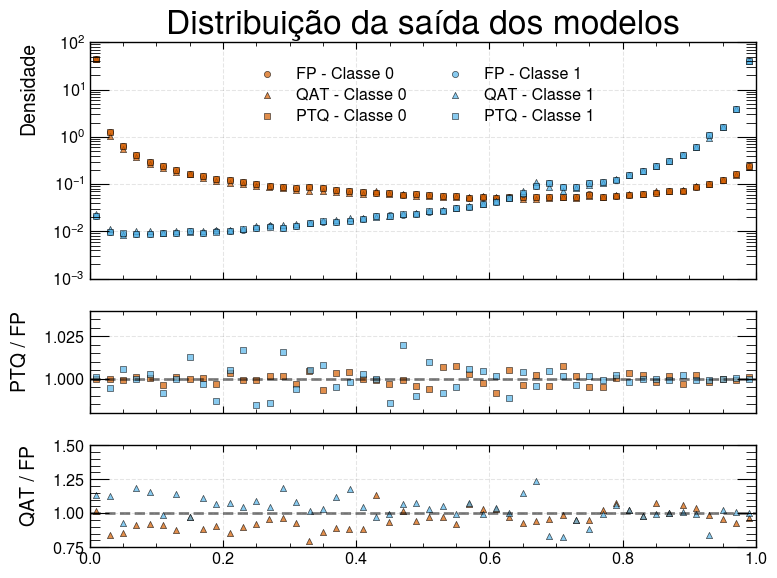

In [12]:
plt.style.use(hep.style.ATLAS)
fig = plt.figure(layout="tight")
grid_spec = GridSpec(8, 1, figure=fig)
hist_ax = fig.add_subplot(grid_spec[:4, 0])
# fig, ax = plt.subplots(3, 1)
hist_ax.grid(linestyle='--', alpha=0.1, color='k')
colors = [
    'red',
    'blue',
    'green',
    'orange',
    'purple',
    'cyan',
    'magenta',
]
class_colors = [
    'C0',
    'C1'
]
for i, (class_label, hist_col) in enumerate(product(range(2), hist_columns)):
    hist_config = hist_columns[hist_col]
    color = class_colors[class_label]
    n, bins = np.histogram(
        hist_config['df'].filter(pl.col('label') == class_label)[hist_col].to_numpy(),
        bins=50,
        density=True
    )
    # n, bins, _ =  ax.hist(
    #     hist_config['df'].filter(pl.col('label') == class_label)[hist_col].to_numpy(),
    #     bins=50,
    #     alpha=0.5,
    #     linestyle=hist_config['linestyle'],
    #     color='white',
    #     label=None,
    #     histtype='step',
    #     linewidth=2,
    #     density=True
    # )
    x = (bins[:-1] + bins[1:])/2
    y = n

    hist_ax.scatter(
        x, y,
        color=color,
        s=20,
        alpha=0.7,
        edgecolor='k',
        linewidth=0.5,
        marker=hist_config['marker'],
        label=f"{hist_config['label']} - Classe {class_label}"
    )
    hist_columns[hist_col][f'y_class_{class_label}'] = y
    hist_columns[hist_col][f'x_class_{class_label}'] = x
# hist_ax.set_xlabel('Saída do Modelo', fontsize='small')
hist_ax.set_ylabel('Densidade', fontsize='medium')
hist_ax.set_yscale('log')
hist_ax.set_title('Distribuição da saída dos modelos')
hist_ax.legend(
    fontsize='small',
    loc='upper center',
    ncols=2
)
hist_ax.tick_params(
    axis='x',          # Apply to x and y axes
    which='both',        # Target major ticks
    # bottom=False,
    labelbottom=False
)
hist_ax.tick_params(
    axis='y',          # Apply to x and y axes
    which='both',        # Target major ticks
    # bottom=False,
    labelsize='small'
)

classes_ratios = {
    'PTQ / FP': {
        'ax': fig.add_subplot(grid_spec[4:6, 0]),
        'numerator': 'ptq.output',
        'denominator': 'fp.output',
        'tick_params':[
            {'axis': 'x', 'which': 'both', 'labelbottom': False},
            {'axis': 'y', 'which': 'both', 'labelsize': 'small'}
        ]
    },
    'QAT / FP': {
        'ax': fig.add_subplot(grid_spec[6:8, 0]),
        'numerator': 'qat.output',
        'denominator': 'fp.output',
        'tick_params':[
            {'axis': 'x', 'which': 'both', 'labelsize': 'small'},
            {'axis': 'y', 'which': 'both', 'labelsize': 'small'}
        ]
    }
}

for ratio_label, ratio_config in classes_ratios.items():
    ratio_ax = ratio_config['ax']
    ratio_ax.grid(linestyle='--', alpha=0.1, color='k')
    ratio_ax.set_ylabel(ratio_label, fontsize='medium')
    ratio_ax.axhline(1, color='k', linestyle='--', alpha=0.5)
    for param in ratio_config['tick_params']:
        ratio_ax.tick_params(**param)
    for color, class_label in zip (class_colors, range(2)):
        
        numerator_config = hist_columns[ratio_config['numerator']]
        denominator_config = hist_columns[ratio_config['denominator']]
        ptq_fp_ratio = numerator_config[f'y_class_{class_label}'] / denominator_config[f'y_class_{class_label}']
        ratio_ax.scatter(
            numerator_config[f'x_class_{class_label}'], ptq_fp_ratio,
            color=color,
            s=20,
            alpha=0.7,
            edgecolor='k',
            linewidth=0.5,
            marker=numerator_config['marker'],
            label=f'Classe {class_label}'
        )

    # ratio_ax.legend(
    #     fontsize='small',
    #     # loc='upper center',
    #     ncols=3
    # )


fig.tight_layout()

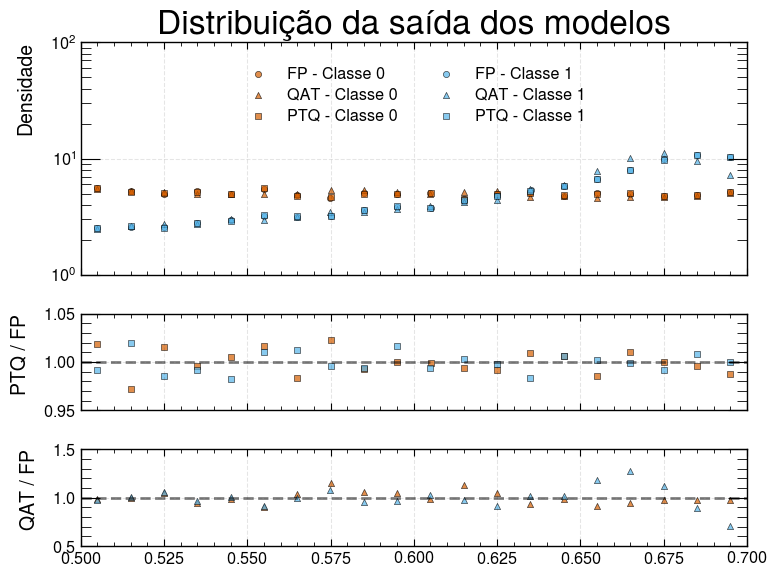

In [13]:
plt.style.use(hep.style.ATLAS)
fig = plt.figure(layout="tight")
grid_spec = GridSpec(8, 1, figure=fig)
hist_ax = fig.add_subplot(grid_spec[:4, 0])
# fig, ax = plt.subplots(3, 1)
hist_ax.grid(linestyle='--', alpha=0.1, color='k')
colors = [
    'red',
    'blue',
    'green',
    'orange',
    'purple',
    'cyan',
    'magenta',
]
class_colors = [
    'C0',
    'C1'
]
for i, (class_label, hist_col) in enumerate(product(range(2), hist_columns)):
    hist_config = hist_columns[hist_col]
    color = class_colors[class_label]
    n, bins = np.histogram(
        hist_config['df'].filter(pl.col('label') == class_label).filter(pl.col(hist_col).is_between(0.5, 0.7))[hist_col].to_numpy(),
        bins=20,
        density=True
    )
    # n, bins, _ =  ax.hist(
    #     hist_config['df'].filter(pl.col('label') == class_label)[hist_col].to_numpy(),
    #     bins=50,
    #     alpha=0.5,
    #     linestyle=hist_config['linestyle'],
    #     color='white',
    #     label=None,
    #     histtype='step',
    #     linewidth=2,
    #     density=True
    # )
    x = (bins[:-1] + bins[1:])/2
    y = n

    hist_ax.scatter(
        x, y,
        color=color,
        s=20,
        alpha=0.7,
        edgecolor='k',
        linewidth=0.5,
        marker=hist_config['marker'],
        label=f"{hist_config['label']} - Classe {class_label}"
    )
    hist_columns[hist_col][f'y_class_{class_label}'] = y
    hist_columns[hist_col][f'x_class_{class_label}'] = x
# hist_ax.set_xlabel('Saída do Modelo', fontsize='small')
hist_ax.set_ylabel('Densidade', fontsize='medium')
hist_ax.set_yscale('log')
hist_ax.set_title('Distribuição da saída dos modelos')
hist_ax.legend(
    fontsize='small',
    loc='upper center',
    ncols=2
)
hist_ax.tick_params(
    axis='x',          # Apply to x and y axes
    which='both',        # Target major ticks
    # bottom=False,
    labelbottom=False
)
hist_ax.tick_params(
    axis='y',          # Apply to x and y axes
    which='both',        # Target major ticks
    # bottom=False,
    labelsize='small'
)

classes_ratios = {
    'PTQ / FP': {
        'ax': fig.add_subplot(grid_spec[4:6, 0]),
        'numerator': 'ptq.output',
        'denominator': 'fp.output',
        'tick_params':[
            {'axis': 'x', 'which': 'both', 'labelbottom': False},
            {'axis': 'y', 'which': 'both', 'labelsize': 'small'}
        ]
    },
    'QAT / FP': {
        'ax': fig.add_subplot(grid_spec[6:8, 0]),
        'numerator': 'qat.output',
        'denominator': 'fp.output',
        'tick_params':[
            {'axis': 'x', 'which': 'both', 'labelsize': 'small'},
            {'axis': 'y', 'which': 'both', 'labelsize': 'small'}
        ]
    }
}

for ratio_label, ratio_config in classes_ratios.items():
    ratio_ax = ratio_config['ax']
    ratio_ax.grid(linestyle='--', alpha=0.1, color='k')
    ratio_ax.set_ylabel(ratio_label, fontsize='medium')
    ratio_ax.axhline(1, color='k', linestyle='--', alpha=0.5)
    for param in ratio_config['tick_params']:
        ratio_ax.tick_params(**param)
    for color, class_label in zip (class_colors, range(2)):
        
        numerator_config = hist_columns[ratio_config['numerator']]
        denominator_config = hist_columns[ratio_config['denominator']]
        ptq_fp_ratio = numerator_config[f'y_class_{class_label}'] / denominator_config[f'y_class_{class_label}']
        ratio_ax.scatter(
            numerator_config[f'x_class_{class_label}'], ptq_fp_ratio,
            color=color,
            s=20,
            alpha=0.7,
            edgecolor='k',
            linewidth=0.5,
            marker=numerator_config['marker'],
            label=f'Classe {class_label}'
        )

    # ratio_ax.legend(
    #     fontsize='small',
    #     # loc='upper center',
    #     ncols=3
    # )


fig.tight_layout()